# Milestone 2: Olist Orders — EDA and Feature Engineering
**Gautham G Shenoy | 4SF25CI054_3A**

This analysis explores 2016–2018 Brazilian e-commerce orders. One row represents one order. Source: [Olist Brazilian E-Commerce dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), CC BY-NC-SA 4.0. The original orders CSV accompanies this notebook. Order and customer IDs identify records; status and five timestamps describe purchase, approval, handoff, delivery and expected delivery. Operations follow the separate-cell inspection, quality checks, distributions and correlations demonstrated in the supplied reference notebook.

Run all cells in order after installing `pandas`, `numpy`, `matplotlib` and `seaborn`.

## 1. Load and inspect the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")

In [2]:
# Load the original CSV from the same folder as this notebook.
df = pd.read_csv("olist_orders_dataset.csv")

In [3]:
# Inspect example orders.
display(df.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
# Dimensions, schema, data types, and memory usage.
print("Original dimensions:", df.shape)
print("Columns:", df.columns.tolist())
df.info(memory_usage="deep")

Original dimensions: (99441, 8)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


## 2. Data quality assessment

In [5]:
# Examine missing values, including percentages.
display(pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean()*100).round(2)}))

,missing,percent
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


In [6]:
# Check exact duplicate records and repeated order IDs.
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate order IDs:", df.order_id.duplicated().sum())

Exact duplicate rows: 0
Duplicate order IDs: 0


In [7]:
# Inspect original categorical values before standardization.
print(df.order_status.value_counts(dropna=False))
print("Unique statuses:", df.order_status.unique())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Unique statuses: <ArrowStringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str


Missing delivery dates are kept as missing because some orders were not delivered. Exact duplicates are removed; inconsistent negative elapsed times are marked missing instead of being silently replaced with zero.

In [8]:
clean=df.drop_duplicates().copy()
clean['order_status']=clean.order_status.str.strip().str.lower()
dates=[c for c in clean if 'timestamp' in c or c.endswith('_date') or c.endswith('_at')]
for c in dates:
    clean[c]=pd.to_datetime(clean[c],errors='coerce')
print('Missing dates after conversion:',clean[dates].isna().sum())

Missing dates after conversion: order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


## 3. Feature engineering
The twelve features describe purchase timing, processing, delivery and lateness. Variables based on later events are useful for retrospective analysis but must be excluded from predictions made at purchase time.

In [9]:
p=clean.order_purchase_timestamp
a=clean.order_approved_at
c=clean.order_delivered_carrier_date
d=clean.order_delivered_customer_date
e=clean.order_estimated_delivery_date
# Features describe when purchases occur and how orders progress.
clean['purchase_year']=p.dt.year
clean['purchase_month']=p.dt.month
clean['purchase_weekday']=p.dt.day_name()
clean['purchase_hour']=p.dt.hour
clean['weekend']=p.dt.dayofweek.ge(5).where(p.notna())
clean['purchase_period']=pd.cut(p.dt.hour,[-1,5,11,17,23],labels=['Night','Morning','Afternoon','Evening'])

In [10]:
clean['approval_hours']=(a-p).dt.total_seconds()/3600
clean['handoff_days']=(c-p).dt.total_seconds()/86400
clean['delivery_days']=(d-p).dt.total_seconds()/86400
clean['estimated_days']=(e-p).dt.total_seconds()/86400
clean['delay_days']=(d-e).dt.total_seconds()/86400
clean['late']=(d>e).where(d.notna() & e.notna())
# Missing delivery dates are expected for some unfinished orders. Preserve them.
# Impossible negative elapsed durations become missing; outliers are retained.
for col in ['approval_hours','handoff_days','delivery_days','estimated_days']:
    invalid=clean[col]<0
    print('Negative',col,':',invalid.sum())
    clean.loc[invalid,col]=np.nan

Negative approval_hours : 0
Negative handoff_days : 166
Negative delivery_days : 0
Negative estimated_days : 0


In [11]:
features=['purchase_year','purchase_month','purchase_weekday','purchase_hour','weekend','purchase_period','approval_hours','handoff_days','delivery_days','estimated_days','delay_days','late']
print('Feature types:',clean[features].dtypes)
print('Feature missing values:',clean[features].isna().sum())
print('Final shape:',clean.shape)

Feature types: purchase_year          int32
purchase_month         int32
purchase_weekday         str
purchase_hour          int32
weekend                 bool
purchase_period     category
approval_hours       float64
handoff_days         float64
delivery_days        float64
estimated_days       float64
delay_days           float64
late                  object
dtype: object
Feature missing values: purchase_year          0
purchase_month         0
purchase_weekday       0
purchase_hour          0
weekend                0
purchase_period        0
approval_hours       160
handoff_days        1949
delivery_days       2965
estimated_days         0
delay_days          2965
late                2965
dtype: int64
Final shape: (99441, 20)


## 4. Descriptive statistics and outliers

In [12]:
# Summarize numeric and categorical variables separately.
display(clean.select_dtypes(include='number').describe().round(2))
display(clean[['order_status','purchase_weekday','purchase_period']].describe())

,purchase_year,purchase_month,purchase_hour,approval_hours,handoff_days,delivery_days,estimated_days,delay_days
count,99441.00,99441.00,99441.00,99281.00,97492.00,96476.00,99441.00,96476.00
mean,2017.54,6.03,14.77,10.42,3.24,12.56,23.77,-11.18
std,0.51,3.23,5.33,26.04,3.57,9.55,8.83,10.19
min,2016.00,1.00,0.00,0.00,0.00,0.53,1.65,-146.02
25%,2017.00,3.00,11.00,0.22,1.13,6.77,18.33,-16.24
50%,2018.00,6.00,15.00,0.34,2.21,10.22,23.24,-11.95
75%,2018.00,8.00,19.00,14.58,4.07,15.72,28.42,-6.39
max,2018.00,12.00,23.00,4509.18,125.78,209.63,155.14,188.98


,order_status,purchase_weekday,purchase_period
count,99441,99441,99441
unique,8,7,4
top,delivered,Monday,Afternoon
freq,96478,16196,38361


In [13]:
q1,q3=clean.delivery_days.quantile([.25,.75]); upper=q3+1.5*(q3-q1)
print('IQR upper bound:',upper,'High outliers:',(clean.delivery_days>upper).sum())

IQR upper bound: 29.15121238425926 High outliers: 4899


The IQR rule identifies unusually long deliveries; it does not prove they are incorrect. Retaining them avoids removing real delays.

## 5. Univariate analysis

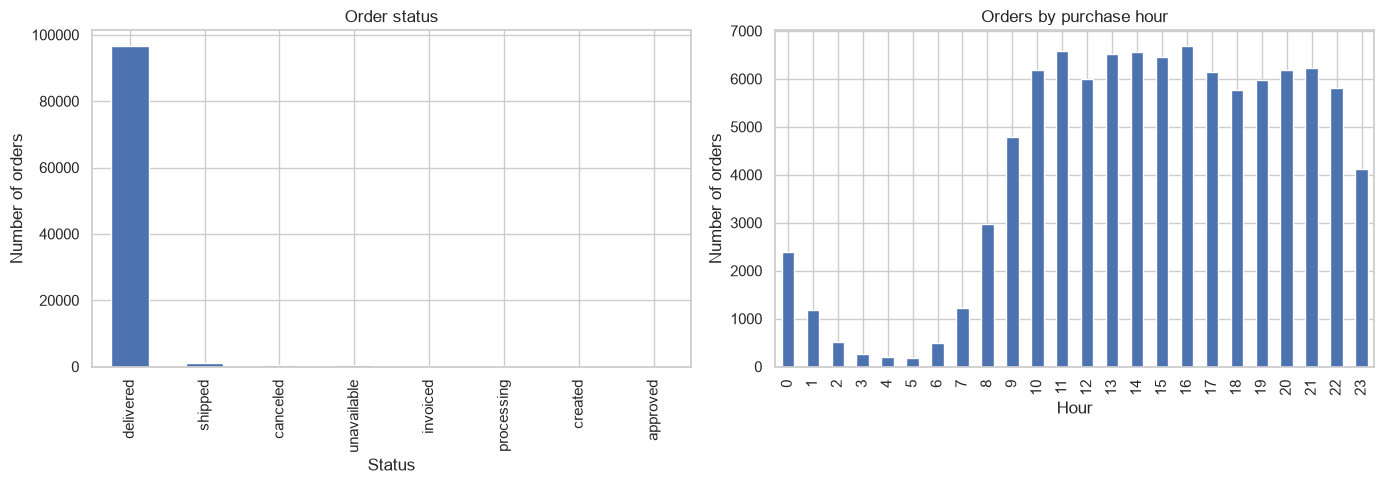

In [14]:
# Order statuses and purchase-hour distributions.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
clean.order_status.value_counts().plot.bar(ax=axes[0], title='Order status', xlabel='Status', ylabel='Number of orders')
clean.purchase_hour.value_counts().sort_index().plot.bar(ax=axes[1], title='Orders by purchase hour', xlabel='Hour', ylabel='Number of orders')
plt.tight_layout(); plt.show()

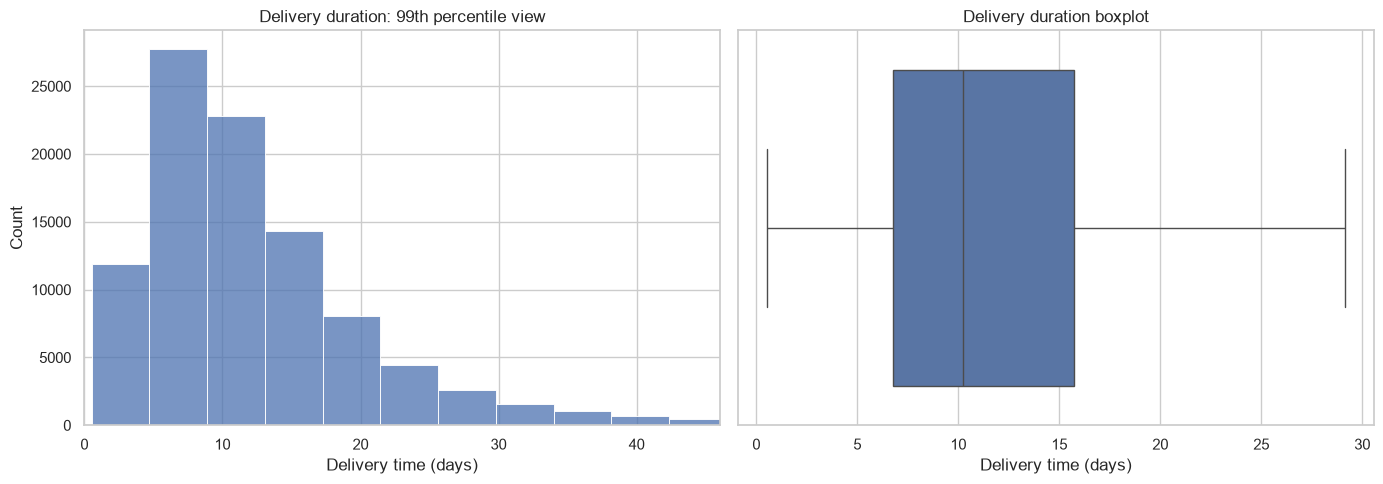

In [15]:
# The histogram is capped only for display; all data remains in calculations.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(clean.delivery_days.dropna(), bins=50, ax=axes[0]); axes[0].set_xlim(0, clean.delivery_days.quantile(.99)); axes[0].set(xlabel='Delivery time (days)', title='Delivery duration: 99th percentile view')
sns.boxplot(x=clean.delivery_days, showfliers=False, ax=axes[1]); axes[1].set(xlabel='Delivery time (days)', title='Delivery duration boxplot')
plt.tight_layout(); plt.show()

## 6. Bivariate and multivariate analysis

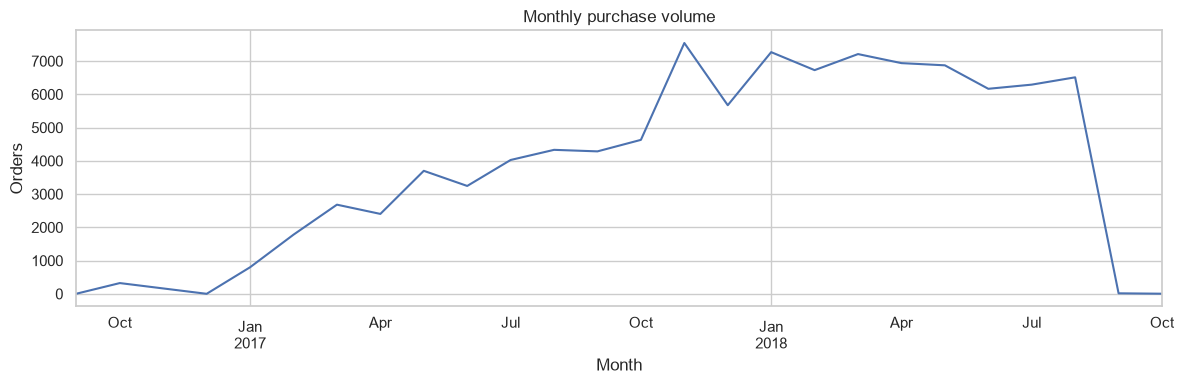

In [16]:
# Monthly order volume reveals time trends; edge months are incomplete.
monthly = clean.groupby(p.dt.to_period('M')).size()
monthly.plot(figsize=(12,4), title='Monthly purchase volume', xlabel='Month', ylabel='Orders'); plt.tight_layout(); plt.show()

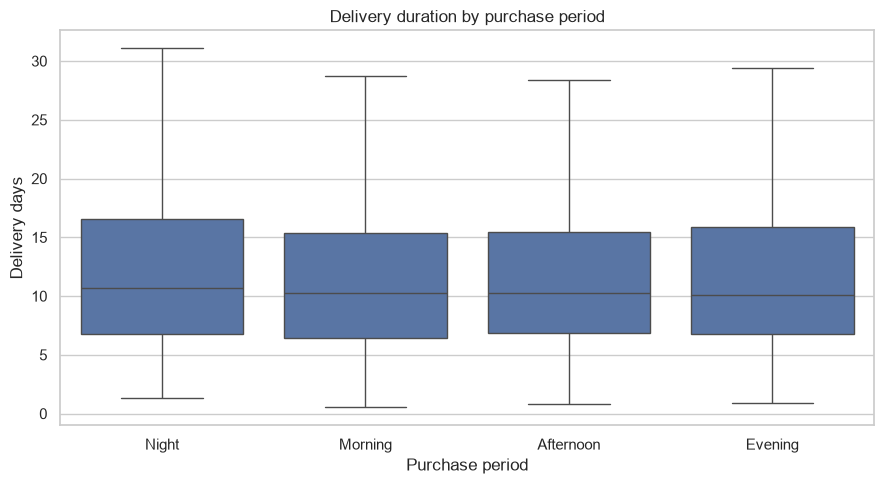

In [17]:
# Compare observed delivery duration across purchase periods.
plt.figure(figsize=(9,5)); sns.boxplot(data=clean, x='purchase_period', y='delivery_days', showfliers=False)
plt.title('Delivery duration by purchase period'); plt.xlabel('Purchase period'); plt.ylabel('Delivery days'); plt.tight_layout(); plt.show()

,approval_hours,handoff_days,delivery_days,estimated_days,delay_days
approval_hours,1.00,0.19,0.08,0.04,0.04
handoff_days,0.19,1.00,0.40,0.21,0.20
delivery_days,0.08,0.40,1.00,0.38,0.61
estimated_days,0.04,0.21,0.38,1.00,-0.50
delay_days,0.04,0.20,0.61,-0.50,1.00


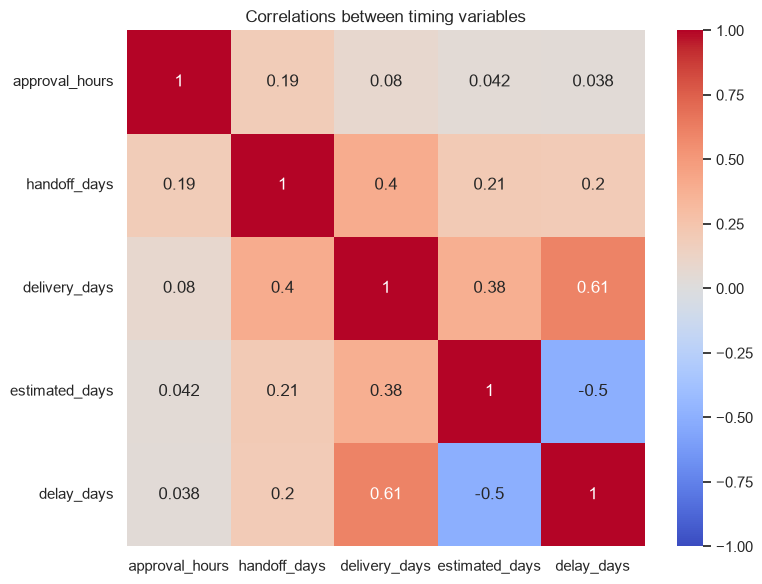

In [18]:
# Pairwise correlations are descriptive and do not establish causation.
timing = ['approval_hours','handoff_days','delivery_days','estimated_days','delay_days']
display(clean[timing].corr().round(2))
plt.figure(figsize=(8,6)); sns.heatmap(clean[timing].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlations between timing variables'); plt.tight_layout(); plt.show()

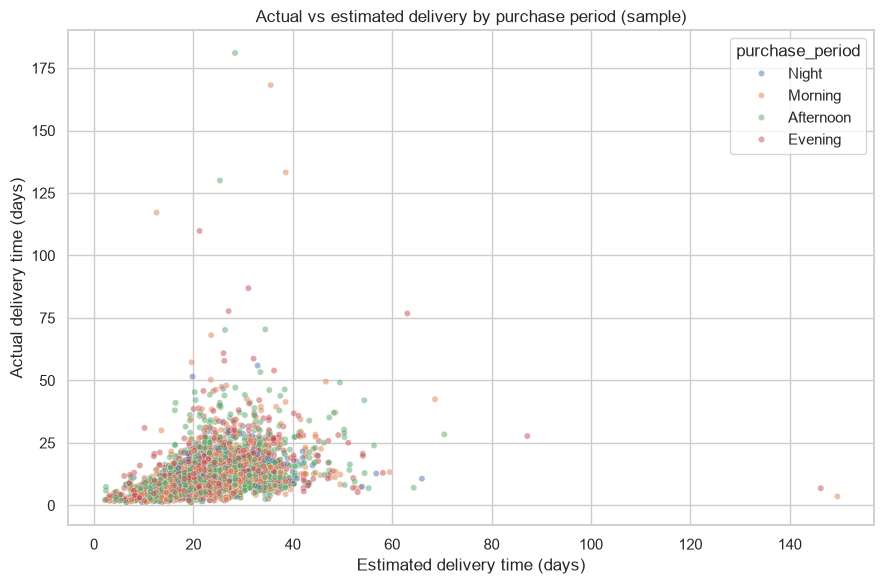

In [19]:
# Multivariate view: delivery vs estimate, colored by purchase period.
sample = clean.dropna(subset=['delivery_days','estimated_days']).sample(n=3000, random_state=42)
plt.figure(figsize=(9,6)); sns.scatterplot(data=sample, x='estimated_days', y='delivery_days', hue='purchase_period', alpha=.5, s=20)
plt.xlabel('Estimated delivery time (days)'); plt.ylabel('Actual delivery time (days)'); plt.title('Actual vs estimated delivery by purchase period (sample)'); plt.tight_layout(); plt.show()

## 7. Findings and limitations

In [20]:
print('OBSERVATIONS')
print('1 Orders:',len(clean),'unique IDs:',clean.order_id.nunique())
print('2 Most common status:',clean.order_status.value_counts().head(1))
print('3 Purchase date range:',p.min(),p.max())
print('4 Busiest hour:',clean.purchase_hour.value_counts().idxmax())
print('5 Most common weekday:',clean.purchase_weekday.value_counts().idxmax())
print('6 Weekend percentage:',round(clean.weekend.dropna().mean()*100,2))
print('7 Median delivery days:',round(clean.delivery_days.median(),2))
print('8 Mean delivery days:',round(clean.delivery_days.mean(),2))
print('9 Known delivery and estimate:',clean.late.notna().sum())
print('10 Late percentage where known:',round(clean.late.dropna().mean()*100,2))
print('11 Median approval hours:',round(clean.approval_hours.median(),2))
print('12 Peak purchase month:',clean.groupby(p.dt.to_period('M')).size().idxmax())
print('13 High delivery outliers retained:',(clean.delivery_days>upper).sum())
print('Limitations: historical marketplace data; missing delivery is not zero; correlation is not causation.')
print('Leakage: approval, handoff, delivery, delay and late features use future events and must be excluded when predicting at purchase time.')

OBSERVATIONS
1 Orders: 99441 unique IDs: 99441
2 Most common status: order_status
delivered    96478
Name: count, dtype: int64
3 Purchase date range: 2016-09-04 21:15:19 2018-10-17 17:30:18
4 Busiest hour: 16
5 Most common weekday: Monday
6 Weekend percentage: 22.98
7 Median delivery days: 10.22
8 Mean delivery days: 12.56
9 Known delivery and estimate: 96476
10 Late percentage where known: 8.11
11 Median approval hours: 0.34
12 Peak purchase month: 2017-11
13 High delivery outliers retained: 4899
Limitations: historical marketplace data; missing delivery is not zero; correlation is not causation.
Leakage: approval, handoff, delivery, delay and late features use future events and must be excluded when predicting at purchase time.


**Interpretation:** The delivered subset has a mean duration above its median, suggesting a right-skewed distribution. The late percentage uses only records with both timestamps. Monthly edge periods are incomplete and the source represents one historical marketplace. Long delays are not automatically errors. Correlations do not establish causality.

**Leakage:** Approval, carrier handoff, actual delivery, delay and late status are future information at purchase time. Exclude them from a purchase-time predictive model. Use the estimated delivery only if it is already known at the intended prediction time.

## 8. Export the transformed dataset

In [21]:
# Save the cleaned data with engineered features.
clean.to_csv('olist_orders_processed.csv', index=False)
print('Saved:', clean.shape)

Saved: (99441, 20)
